## <font color="orange">Part 1: K-Nearest Neighbors</font>

# Import Libraries

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

## <font color="orange">Question 1</font>

## Loading the file

In [18]:
airline_df = pd.read_csv('airline_passenger_satisfaction.csv')
data_dictionary = pd.read_csv('airlines_data_dictionary.csv')

In [19]:
print('Shape:', airline_df.shape)
airline_df.head()

Shape: (129880, 24)


,ID,Gender,Age,Customer Type,Type of Travel,Class,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,...,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction
0,1,Male,48,First-time,Business,Business,821,2,5.0,3,...,3,5,2,5,5,5,3,5,5,Neutral or Dissatisfied
1,2,Female,35,Returning,Business,Business,821,26,39.0,2,...,5,4,5,5,3,5,2,5,5,Satisfied
2,3,Male,41,Returning,Business,Business,853,0,0.0,4,...,3,5,3,5,5,3,4,3,3,Satisfied
3,4,Male,50,Returning,Business,Business,1905,0,0.0,2,...,5,5,5,4,4,5,2,5,5,Satisfied
4,5,Female,49,Returning,Business,Business,3470,0,1.0,3,...,3,4,4,5,4,3,3,3,3,Satisfied


In [20]:
print('Shape:', data_dictionary.shape)
data_dictionary

Shape: (24, 2)


,Field,Description
0,ID,Unique passenger identifier
1,Gender,Gender of the passenger (Female/Male)
2,Age,Age of the passenger
3,Customer Type,Type of airline customer (First-time/Returning)
4,Type of Travel,Purpose of the flight (Business/Personal)
5,Class,Travel class in the airplane for the passenger...
6,Flight Distance,Flight distance in miles
7,Departure Delay,Flight departure delay in minutes
8,Arrival Delay,Flight arrival delay in minutes
9,Departure and Arrival Time Convenience,Satisfaction level with the convenience of the...


## Separating the data types (numerical categorical, ratings)

In [21]:
airline_df = airline_df.drop(columns=['ID']) # The ID column is not useful for analysis.

numerical_cols = ['Age', 'Flight Distance', 'Departure Delay', 'Arrival Delay']
nominal_cols = ['Gender', 'Customer Type', 'Type of Travel', 'Class']
target_col = 'Satisfaction'
rating_cols = [col for col in airline_df.columns if col not in numerical_cols + nominal_cols + [target_col]]

print('Rating columns:', len(rating_cols))
airline_df[numerical_cols].describe().T

Rating columns: 14


,count,mean,std,min,25%,50%,75%,max
Age,129880.0,39.427957,15.119360,7.0,27.0,40.0,51.0,85.0
Flight Distance,129880.0,1190.316392,997.452477,31.0,414.0,844.0,1744.0,4983.0
Departure Delay,129880.0,14.713713,38.071126,0.0,0.0,0.0,12.0,1592.0
Arrival Delay,129487.0,15.091129,38.465650,0.0,0.0,0.0,13.0,1584.0


## Replacing the misssing values

In [22]:
airline_df.isna().sum()

,0
Gender,0
Age,0
Customer Type,0
Type of Travel,0
Class,0
Flight Distance,0
Departure Delay,0
Arrival Delay,393
Departure and Arrival Time Convenience,0
Ease of Online Booking,0


Arrival Delay is missing 393 values. We can assume it is the same as the Departure Delay, because Arrival Delay is very correlated to the Departure Delay. This way, we replace the missing values with the corresponding Departure Delay.

In [23]:
airline_df['Arrival Delay'] = airline_df['Arrival Delay'].fillna(airline_df['Departure Delay'])

## Ploting the numerical data

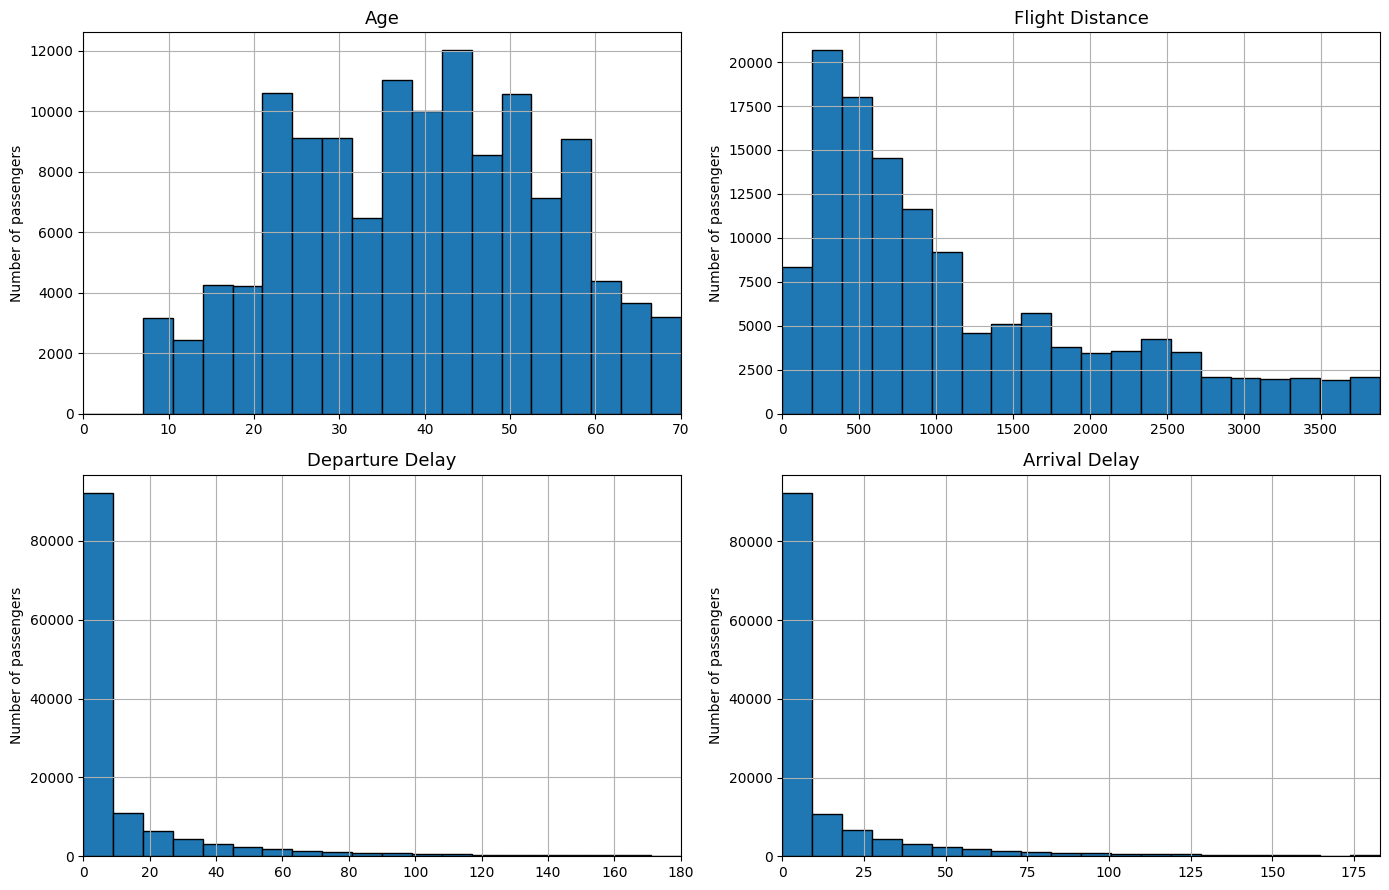

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for i in range(len(numerical_cols)):
    col = numerical_cols[i]
    ax = axes[i]
    limite = airline_df[col].quantile(0.99) # We set the limit to the 99th percentile
    airline_df[col].hist(bins=20, edgecolor='black', ax=ax, range=(0, limite))
    ax.set_xlim(0, limite)
    ax.set_title(col, fontsize=13)
    ax.set_ylabel('Number of passengers')

plt.tight_layout()
plt.show()

## Ploting the categorical data

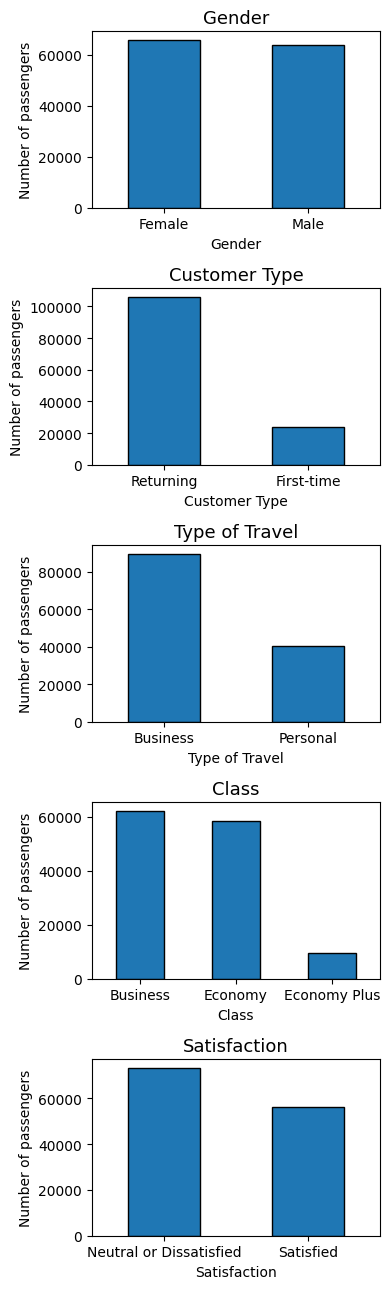

In [25]:
cols_to_plot = nominal_cols + [target_col]

fig, axes = plt.subplots(5, 1, figsize=(4, 13))
axes = axes.flatten()

for i in range(len(cols_to_plot)):
    col = cols_to_plot[i]
    ax = axes[i]
    airline_df[col].value_counts().plot(kind='bar', edgecolor='black', ax=ax)
    ax.set_title(col, fontsize=13)
    ax.set_ylabel('Number of passengers')
    ax.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

## Ploting the ratings

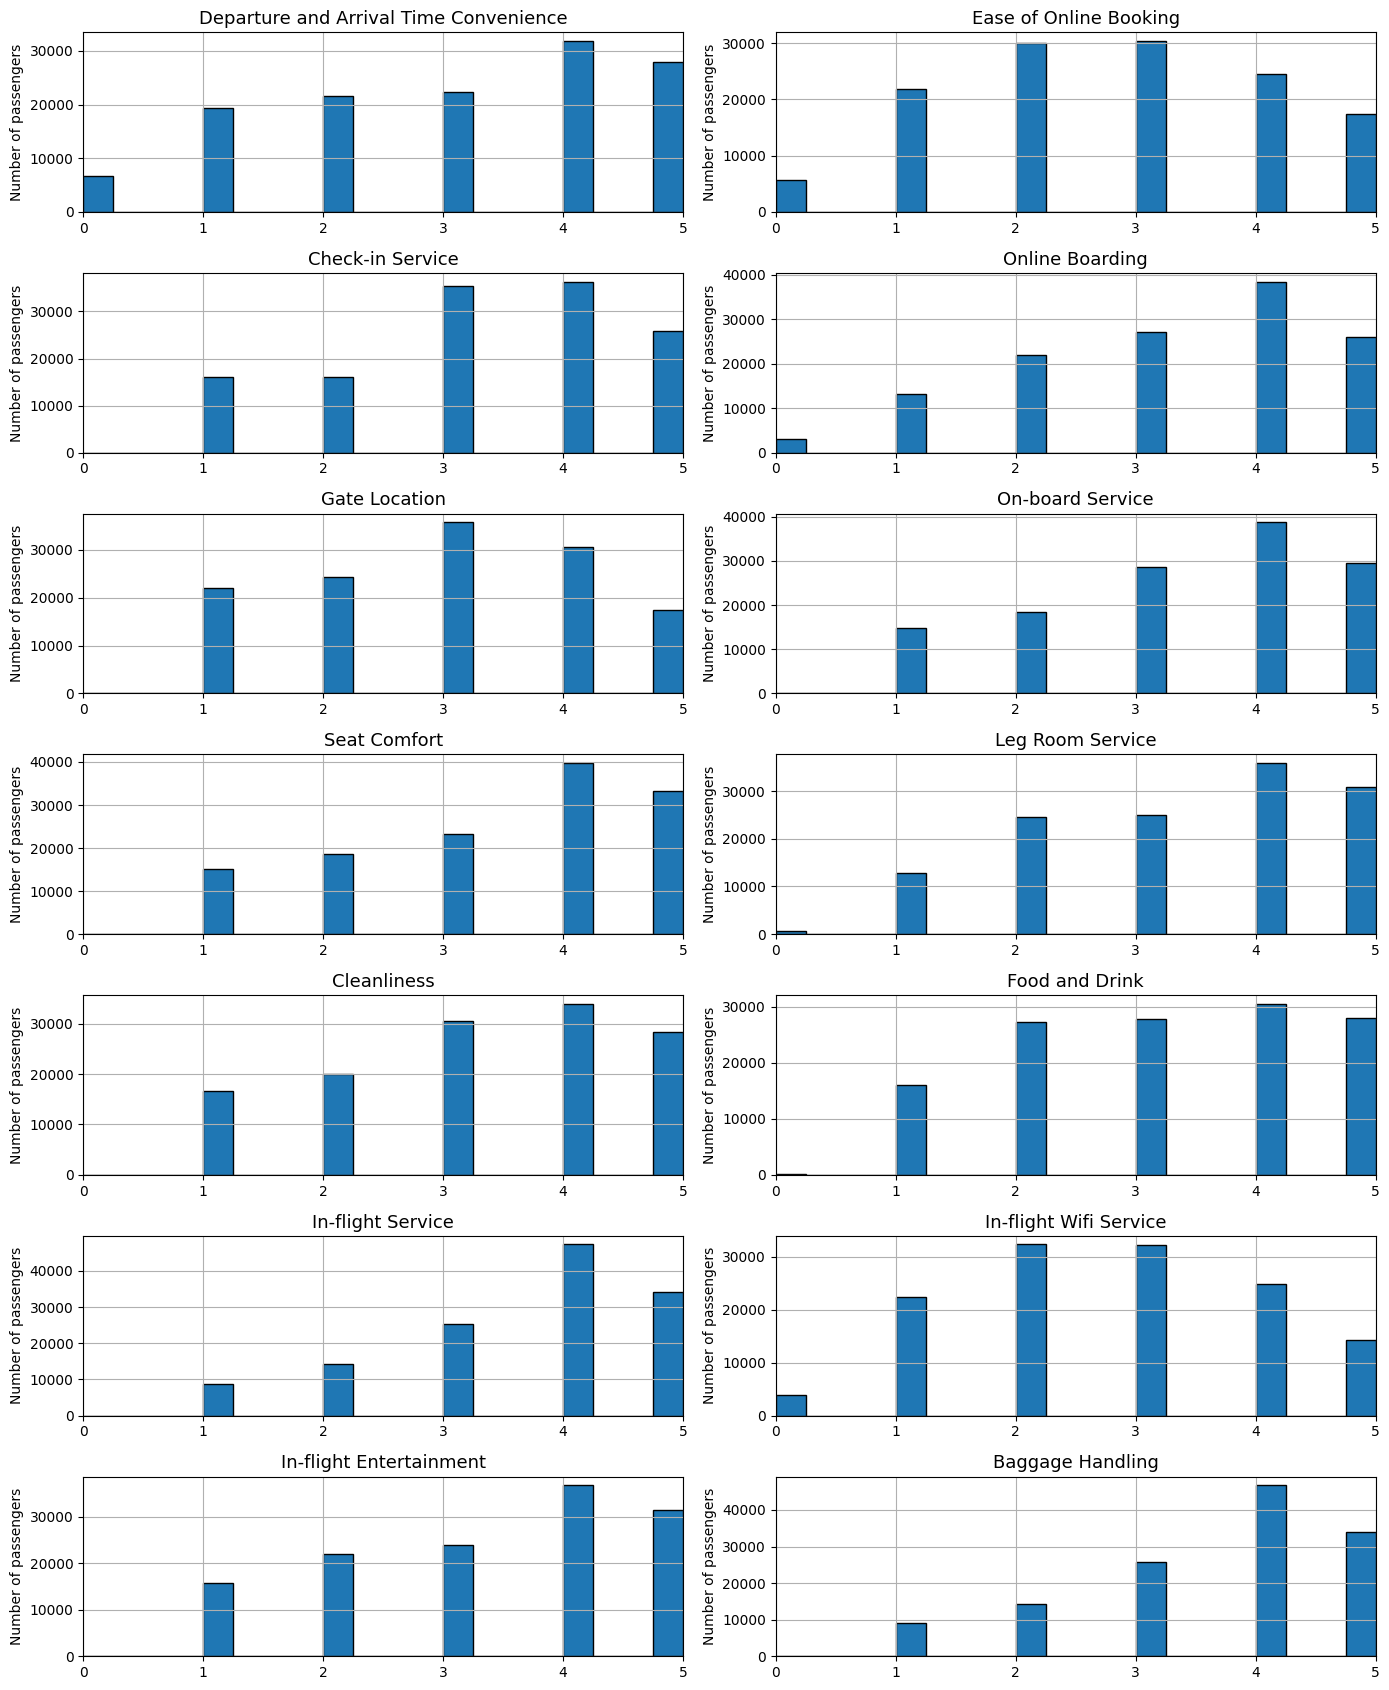

In [26]:
fig, axes = plt.subplots(7, 2, figsize=(14, 17))
axes = axes.flatten()

for i in range(len(rating_cols)):
    col = rating_cols[i]
    ax = axes[i]
    limite = airline_df[col].quantile(0.99) # We set the limit to the 99th percentile
    airline_df[col].hist(bins=20, edgecolor='black', ax=ax, range=(0, limite))
    ax.set_xlim(0, limite)
    ax.set_title(col, fontsize=13)
    ax.set_ylabel('Number of passengers')

plt.tight_layout()
plt.show()

## Class balance

In [27]:
class_balance = pd.DataFrame({'Count': airline_df[target_col].value_counts(),'Percentage (%)': (airline_df[target_col].value_counts(normalize=True) * 100).round(2)})
class_balance

,Count,Percentage (%)
Satisfaction,,
Neutral or Dissatisfied,73452,56.55
Satisfied,56428,43.45


There are more neutral or dissatisfied customers than satisfied customers, the classes are imbalanced.

## <font color="orange">Question 2</font>

For the categorical variables that have only two values, we can use binary encoding.
For the class, we simply assign 0, 1 and 2 to Economy, Economy Plus and Business respectively.

In [28]:
binary_mappings = {
    'Gender': {'Female': 0, 'Male': 1},
    'Customer Type': {'First-time': 0, 'Returning': 1},
    'Type of Travel': {'Personal': 0, 'Business': 1},
    'Satisfaction': {'Neutral or Dissatisfied': 0, 'Satisfied': 1},
}
class_order = {'Economy': 0, 'Economy Plus': 1, 'Business': 2}

encoded_df = airline_df.copy()
for col, mapping in binary_mappings.items():
    encoded_df[col] = encoded_df[col].map(mapping)

encoded_df['Class'] = encoded_df['Class'].map(class_order)

encoded_df.head()

,Gender,Age,Customer Type,Type of Travel,Class,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,Ease of Online Booking,...,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction
0,1,48,0,1,2,821,2,5.0,3,3,...,3,5,2,5,5,5,3,5,5,0
1,0,35,1,1,2,821,26,39.0,2,2,...,5,4,5,5,3,5,2,5,5,1
2,1,41,1,1,2,853,0,0.0,4,4,...,3,5,3,5,5,3,4,3,3,1
3,1,50,1,1,2,1905,0,0.0,2,2,...,5,5,5,4,4,5,2,5,5,1
4,0,49,1,1,2,3470,0,1.0,3,3,...,3,4,4,5,4,3,3,3,3,1


## <font color="orange">Question 3</font>

In [29]:
input_df = encoded_df.drop(columns=['Satisfaction'])
targets_df = encoded_df['Satisfaction']

x = input_df.to_numpy()
y = targets_df.to_numpy()
x.shape, y.shape

((129880, 22), (129880,))

In [30]:
seed = 0
test_size = 0.1

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=test_size, random_state=seed)
x_train.shape, y_train.shape, x_test.shape, y_test.shape

((116892, 22), (116892,), (12988, 22), (12988,))

## <font color="orange">Question 4</font>

Some of the numerical features (Flight Distance, Delay) are a lot bigger in scale than the binary coding of the categorical data and would distort the results of the KNN classifier. The best way to numalize the data is the MinMaxScaler, because it maps every numerical figure between 0 and 1. This way, all of the variables contribute the same to the KNN classifier.

In [31]:
scaler = MinMaxScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)


## <font color="orange">Question 5</font>

In [32]:
N = x_train.shape[0]
k_sqrt_n = int(np.sqrt(N))
k_sqrt_n = k_sqrt_n if k_sqrt_n % 2 == 1 else k_sqrt_n + 1

k_values = [3, 5, 15, 51, 151, k_sqrt_n]
weight_options = ['uniform', 'distance']
print(f'N = {N:,} training examples  ->  sqrt(N) ≈ {k_sqrt_n}')

results = []
for k in k_values:
    for weights in weight_options:
        knn = KNeighborsClassifier(n_neighbors=k, weights=weights, metric='euclidean', n_jobs=-1)
        knn.fit(x_train, y_train)
        train_acc = accuracy_score(y_train, knn.predict(x_train))
        test_acc = accuracy_score(y_test, knn.predict(x_test))
        results.append({'k': k, 'Weights': weights, 'Train Accuracy': train_acc, 'Test Accuracy': test_acc})


results_df = pd.DataFrame(results)

best = results_df.loc[results_df['Test Accuracy'].idxmax()]
print(f"\nBest combination: k={best['k']}, weights={best['Weights']}, test accuracy = {best['Test Accuracy']:.4f}")

results_df

N = 116,892 training examples  ->  sqrt(N) ≈ 341

Best combination: k=5, weights=distance, test accuracy = 0.9306


,k,Weights,Train Accuracy,Test Accuracy
0,3,uniform,0.960288,0.929088
1,3,distance,1.000000,0.928857
2,5,uniform,0.950741,0.930551
3,5,distance,1.000000,0.930628
4,15,uniform,0.937087,0.930012
5,15,distance,1.000000,0.930551
6,51,uniform,0.926548,0.922390
7,51,distance,1.000000,0.924469
8,151,uniform,0.913767,0.910841
9,151,distance,1.000000,0.912766


## <font color="orange">Part 2 – Timeseries Forecasting</font>

In [33]:
import holidays
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
import yfinance as yf
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.stattools import grangercausalitytests

## <font color="orange">Question 1</font>

# Download Financial Data

Download 5 years of USD Index. Columns Volume, Dividends and Stock Splits are not required, since they are constant and equal to 0.0

In [34]:
ticker_symbol = 'DX-Y.NYB'

ticker = yf.Ticker(ticker_symbol)
df = ticker.history(period='5y').drop(columns=['Volume', 'Dividends', 'Stock Splits']).reset_index(drop=False)
df

,Date,Open,High,Low,Close
0,2021-10-29 00:00:00-04:00,93.360001,94.300003,93.320000,94.120003
1,2021-11-01 00:00:00-04:00,94.129997,94.309998,93.860001,93.879997
2,2021-11-02 00:00:00-04:00,93.930000,94.129997,93.820000,94.089996
3,2021-11-03 00:00:00-04:00,94.120003,94.209999,93.820000,93.860001
4,2021-11-04 00:00:00-04:00,93.860001,94.470001,93.830002,94.349998
...,...,...,...,...,...
1252,2026-10-23 00:00:00-04:00,101.570000,101.849998,101.489998,101.809998
1253,2026-10-26 00:00:00-04:00,101.779999,102.059998,101.580002,101.959999
1254,2026-10-27 00:00:00-04:00,102.029999,102.400002,101.989998,102.320000
1255,2026-10-28 00:00:00-04:00,102.370003,102.489998,102.050003,102.190002


# Construct Line Plot of HLC Data

In [35]:
fig = px.line(df, x='Date', y=['High', 'Close', 'Low'], title='USD Price Index from 2021 to 2026')
fig.show()

Open: Value of the index at the start day.
High: Highest value reached during the day.
Low: Lowest value reached during the day.
Close: Value at the end of the trading day.
Volume: Number of units traded during the day.

In [36]:
price_cols = ['Open', 'High', 'Low', 'Close']
df[price_cols].describe().T[['mean', 'std', 'min', 'max']].round(3)

,mean,std,min,max
Open,102.261,3.805,93.36,114.19
High,102.594,3.857,94.13,114.78
Low,101.939,3.738,93.32,113.33
Close,102.274,3.801,93.86,114.11


## <font color="orange">Question 2</font>

From the plot, the High, Low and Close series are not stationary:

Indeed, the mean changes over time. The index moves in long trends. There is no constant level the series always returns to.
Furthermore, the variance changes over time. Some years are calm (2019: the index stays within 95-99), others show much larger variance (2020, 2022).
Strong persistence: today's value is almost equal to yesterday's value, so a shock is propagated through the following days.

Since High, Low and Close stay close together everyday, we can say all three series are the same, non-stationary.

## <font color="orange">Question 3</font>

## <font color="orange">Question 4</font>

# Train-Test Split

Test set should start 1 time step after the end of train set.

In [37]:
train_size = 0.7
history_size = 30

num_train_samples = int(df.shape[0]*train_size)
train_df = df.iloc[:num_train_samples]
test_df = df.iloc[num_train_samples - history_size:]

train_df.shape, test_df.shape

((879, 5), (408, 5))

## <font color="orange">Question 5</font>

# Construct Timeframes

*   x = <x[0], x[1], x[2], ... x[H-1]>
*   y = x[H]

where x is (Open(t), High(t), Low(t), Close(t))

**Important: Past target must be included in x to achieve good accuracy**

In [38]:
def construct_timeframes(df, H):
    inputs = df.drop(columns=['Date']).to_numpy(dtype=np.float64)
    x = np.array([inputs[i-H: i].flatten() for i in range(H, df.shape[0])])
    y = df['Close'].to_numpy(dtype=np.float64)[H:]
    return x, y

# Verify Timeframes

In [39]:
train_df.head(5)

,Date,Open,High,Low,Close
0,2021-10-29 00:00:00-04:00,93.360001,94.300003,93.320000,94.120003
1,2021-11-01 00:00:00-04:00,94.129997,94.309998,93.860001,93.879997
2,2021-11-02 00:00:00-04:00,93.930000,94.129997,93.820000,94.089996
3,2021-11-03 00:00:00-04:00,94.120003,94.209999,93.820000,93.860001
4,2021-11-04 00:00:00-04:00,93.860001,94.470001,93.830002,94.349998


In [40]:
x_train, y_train = construct_timeframes(train_df, H=4)
print('x:', x_train[0],'\ny:', y_train[0])

x: [93.36000061 94.30000305 93.31999969 94.12000275 94.12999725 94.30999756
 93.86000061 93.87999725 93.93000031 94.12999725 93.81999969 94.08999634
 94.12000275 94.20999908 93.81999969 93.86000061] 
y: 94.3499984741211


# Fit Linear Regression Model

Setting H = 30

In [41]:
x_train, y_train = construct_timeframes(train_df, history_size)
x_test, y_test = construct_timeframes(test_df, history_size)

x_train.shape, y_train.shape, x_test.shape, y_test.shape

((849, 120), (849,), (378, 120), (378,))

<Axes: title={'center': 'Train-Test MAE of Linear Regression with H=30'}, xlabel='Dataset', ylabel='MAE'>

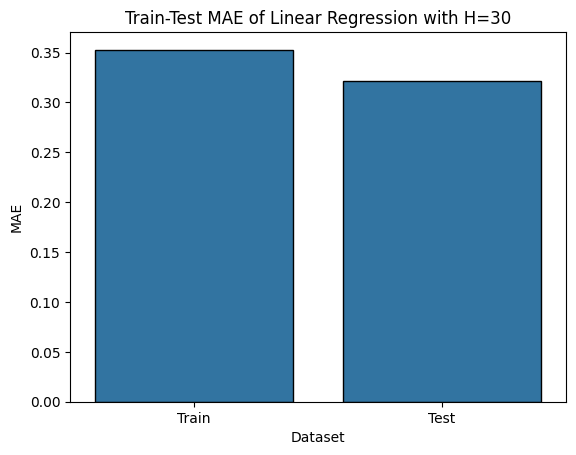

In [42]:
model = LinearRegression()
model.fit(x_train, y_train)

y_pred = model.predict(x_train)
train_mae = mean_absolute_error(y_true=y_train, y_pred=y_pred)
y_pred = model.predict(x_test)
test_mae = mean_absolute_error(y_true=y_test, y_pred=y_pred)

metrics_df = pd.DataFrame({'Dataset': ['Train', 'Test'], 'MAE': [train_mae, test_mae]})
ax = sns.barplot(metrics_df, x='Dataset', y='MAE', edgecolor='black')
ax.set_title('Train-Test MAE of Linear Regression with H=30')
ax

# Visualize Predictions

In [43]:
train_dates = train_df['Date'].iloc[history_size:]
test_dates = test_df['Date'].iloc[history_size:]

# Create figure
fig = go.Figure()

# Training data (last history_size samples only)
fig.add_trace(go.Scatter(
    x=train_dates.iloc[-history_size:],
    y=np.ravel(y_train)[-history_size:],
    mode='lines',
    name='Train',
    line=dict(color='royalblue', width=2)
))

# Test actual values
fig.add_trace(go.Scatter(
    x=test_dates,
    y=np.ravel(y_test),
    mode='lines',
    name='Test (Actual)',
    line=dict(color='royalblue', width=2, dash='dash')
))

# Vertical dashed line separating train/test
fig.add_shape(
    type='line',
    x0=test_dates.iloc[0],
    x1=test_dates.iloc[0],
    y0=0,
    y1=1,
    xref='x',
    yref='paper',
    line=dict(color='black', width=2, dash='dash')
)

# Prediction line for test set
fig.add_trace(go.Scatter(
    x=test_dates,
    y=np.ravel(y_pred),
    mode='lines',
    name='Test (Predicted)',
    line=dict(color='#E63946', width=2.5)
))

# Layout
fig.update_layout(
    title='USD Price Index — Close Price Prediction',
    xaxis_title='Date',
    yaxis_title='Price ($)',
    template='plotly_white',
    legend=dict(x=0.01, y=0.99),
    hovermode='x unified'
)

fig.show()

# Apply Log Returns Transformation

In [44]:
vars = ['Open', 'High', 'Low', 'Close']
df_logr = df.copy()
df_logr[vars] = np.log(df_logr[vars]/df_logr[vars].shift(1))
df_logr

,Date,Open,High,Low,Close
0,2021-10-29 00:00:00-04:00,NaN,NaN,NaN,NaN
1,2021-11-01 00:00:00-04:00,0.008214,0.000106,0.005770,-0.002553
2,2021-11-02 00:00:00-04:00,-0.002127,-0.001910,-0.000426,0.002234
3,2021-11-03 00:00:00-04:00,0.002021,0.000850,0.000000,-0.002447
4,2021-11-04 00:00:00-04:00,-0.002766,0.002756,0.000107,0.005207
...,...,...,...,...,...
1252,2026-10-23 00:00:00-04:00,-0.001377,-0.000294,0.000394,0.001966
1253,2026-10-26 00:00:00-04:00,0.002065,0.002060,0.000886,0.001472
1254,2026-10-27 00:00:00-04:00,0.002453,0.003326,0.004028,0.003525
1255,2026-10-28 00:00:00-04:00,0.003327,0.000878,0.000588,-0.001271


# Convert Log Returns to Absolute Price

$lr_{t+1} = \ln(\frac{y_{t+1}}{y_{t}})$

$y_{t+1} = y_t * e^{lr_{t+1}}$

Inevitably, the first sample will be lost, as its log-return transformation cannot be defined (x[-1] does not exist).

In [45]:
def log_returns_to_absolute_prices(prices, log_returns):
    return prices * np.exp(log_returns)

In [46]:
valid_df = pd.DataFrame({
    'Date': df['Date'].iloc[: 6],
    'Close': df['Close'].iloc[: 6],
    'CLose-Log-Returns': df_logr['Close'].iloc[: 6]
})
valid_df

,Date,Close,CLose-Log-Returns
0,2021-10-29 00:00:00-04:00,94.120003,NaN
1,2021-11-01 00:00:00-04:00,93.879997,-0.002553
2,2021-11-02 00:00:00-04:00,94.089996,0.002234
3,2021-11-03 00:00:00-04:00,93.860001,-0.002447
4,2021-11-04 00:00:00-04:00,94.349998,0.005207
5,2021-11-05 00:00:00-04:00,94.320000,-0.000318


In [47]:
log_returns_to_absolute_prices(
    prices=valid_df['Close'].iloc[: -1].to_numpy(),
    log_returns=valid_df['CLose-Log-Returns'].iloc[1:].to_numpy()
)

array([93.87999725, 94.08999634, 93.86000061, 94.34999847, 94.31999969])

# Check Whether High can Predict Close

Variables that can estimate the target variable are considered beneficial.

In [48]:
data = train_df[['Close', 'Open']]

# Computing log-returns (converting to stationary series).
data = np.log(data/data.shift(1)).dropna()

# Test up to history_size lags
results = grangercausalitytests(data[['Close', 'Open']], maxlag=history_size)

# Extract p-values
p_values = {
    lag: results[lag][0]['ssr_ftest'][1]
    for lag in range(1, history_size + 1)
}
results_df = pd.DataFrame({'Lag (H)': list(p_values.keys()), 'P-value': list(p_values.values())})
results_df['Significant'] = results_df['P-value'] < 0.05
results_df

,Lag (H),P-value,Significant
0,1,0.006791,True
1,2,0.879554,False
2,3,0.424651,False
3,4,0.922236,False
4,5,0.647700,False
5,6,0.887712,False
6,7,0.937569,False
7,8,0.727068,False
8,9,0.810635,False
9,10,0.794107,False


# Extracting Temporal Features

In [49]:
# Calendar features
df['Month'] = df['Date'].dt.month
df['DayOfWeek'] = df['Date'].dt.dayofweek  # Monday=0, Sunday=6

# US & NYSE holidays
us_holidays = holidays.country_holidays('US')
nyse_holidays = holidays.financial_holidays('NYSE')

# Global events
global_events = {
    'NewYearsDay': (1, 1),
    'ValentinesDay': (2, 14),
    'WomensDay': (3, 8),
    'AprilFools': (4, 1),
    'EarthDay': (4, 22),
    'LabourDay': (5, 1),
    'EnvironmentDay': (6, 5),
    'Halloween': (10, 31),
    'ChristmasEve': (12, 24),
    'ChristmasDay': (12, 25),
    'BoxingDay': (12, 26),
    'NewYearsEve': (12, 31),
}

event_dates = set(global_events.values())

# Combine US holidays, NYSE holidays, and global events
df['IsHoliday'] = df['Date'].dt.date.map(
    lambda d: int(
        d in us_holidays
        or d in nyse_holidays
        or (d.month, d.day) in event_dates
    )
)

df

,Date,Open,High,Low,Close,Month,DayOfWeek,IsHoliday
0,2021-10-29 00:00:00-04:00,93.360001,94.300003,93.320000,94.120003,10,4,0
1,2021-11-01 00:00:00-04:00,94.129997,94.309998,93.860001,93.879997,11,0,0
2,2021-11-02 00:00:00-04:00,93.930000,94.129997,93.820000,94.089996,11,1,0
3,2021-11-03 00:00:00-04:00,94.120003,94.209999,93.820000,93.860001,11,2,0
4,2021-11-04 00:00:00-04:00,93.860001,94.470001,93.830002,94.349998,11,3,0
...,...,...,...,...,...,...,...,...
1252,2026-10-23 00:00:00-04:00,101.570000,101.849998,101.489998,101.809998,10,4,0
1253,2026-10-26 00:00:00-04:00,101.779999,102.059998,101.580002,101.959999,10,0,0
1254,2026-10-27 00:00:00-04:00,102.029999,102.400002,101.989998,102.320000,10,1,0
1255,2026-10-28 00:00:00-04:00,102.370003,102.489998,102.050003,102.190002,10,2,0


In [50]:
df['IsHoliday'].value_counts()

,count
IsHoliday,
0,1210
1,47
